# 📚 Lecture 11 Activity Notebook: Topic Modeling
## AA640: Data Analytics and Text Mining
### Bryant University | Prof. Gianluca Brero

---

**IMPORTANT:** *Before starting, save a copy to your Drive via `File > "Save a copy in Drive"`*

### 🎯 Estimated Time: 90 Minutes

#### 💻 This is a REMOTE lecture
Since we're working remotely today, this notebook has **extra-detailed explanations** in every section. Read the markdown cells carefully — they replace the in-person lecture walkthrough.

#### In-Class Schedule

| Time | Clock | Block |
|------|-------|-------|
| 30 min | 6:30pm | Lecture: What is Topic Modeling? |
| 20 min | 7:00pm | **Activity 1** — Train LDA on Newspaper Articles |
| 30 min | 7:20pm | Lecture: Tuning & Interpretation |
| 30 min | 7:50pm | Break + Quiz |
| 20 min | 8:20pm | **Activity 2** — Tune Model, Compare Newspapers |
| 30 min | 8:40pm | Open time — questions, finish notebook |

#### After-Class Activities (~30 min)
*Complete these on your own after lecture.*

| Activity | Topic | Time |
|----------|-------|------|
| Activity 3 | Single-Document Topic Analysis | ~15 min |
| Activity 4 | Topic Coverage Bar Chart | ~15 min |

### ⚙️ How to Use This Notebook
1. **Read** each section carefully — especially the markdown explanations (this is a remote lecture!)
2. **Run** the example cells first to see how things work
3. **Complete** the activities marked with 📝
4. **Check** your answers against the expected output

> 💡 **Tip:** If you get stuck, re-read the demo cell right above the activity — the pattern is always there!

## Setup: Install and Import Libraries

We need a few libraries for today:
- **gensim** — the main library for topic modeling (LDA)
- **pyLDAvis** — creates interactive topic visualizations
- **datasets** — lets us download the American Stories dataset from Hugging Face

Run the cell below to install them. This may take a minute.

In [ ]:
!pip install -q gensim pyLDAvis "datasets<4.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 43.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 61.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 15.6 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

print("Setup complete!")

Setup complete!


---
# 📰 Loading the Dataset: American Stories (1958)

We'll use the **American Stories** dataset from Hugging Face — a collection of digitized newspaper articles from the United States spanning 1770–1964.

**What makes this dataset interesting:**
- Articles were scanned from microfilm and converted to text using OCR (optical character recognition)
- This means the text has some quirks: missing letters, garbled words, and artifacts from the scanning process
- Each article includes metadata: newspaper name, date, page, headline

We'll load articles from **1958** and sample 1,000 of them to keep things fast.

> 💡 **Note:** The first time you run this, it downloads ~200MB of data. Be patient!

In [ ]:
from datasets import load_dataset

# Download data for the year 1958
dataset = load_dataset("dell-research-harvard/AmericanStories",
                       "subset_years",
                       year_list=["1958"],
                       trust_remote_code=True)
print(dataset)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

AmericanStories.py: 0.00B [00:00, ?B/s]

Only taking a subset of years. Change name to 'all_years' to use all years in the dataset.
{'1958': 'https://huggingface.co/datasets/dell-research-harvard/AmericanStories/resolve/main/faro_1958.tar.gz'}


faro_1958.tar.gz:   0%|          | 0.00/431M [00:00<?, ?B/s]

Generating 1958 split: 0 examples [00:00, ? examples/s]

Loading associated
DatasetDict({
    1958: Dataset({
        features: ['article_id', 'newspaper_name', 'edition', 'date', 'page', 'headline', 'byline', 'article'],
        num_rows: 586919
    })
})


In [ ]:
# Convert to pandas and sample 1,000 articles
df_all = dataset['1958'].to_pandas()
df = df_all.sample(n=1000, random_state=33).copy()
df = df.reset_index(drop=True)

print(f"Dataset: {df.shape[0]} rows, {df.shape[1]} columns")
print()
print("Columns:", list(df.columns))
print()
df.head()

Dataset: 1000 rows, 8 columns

Columns: ['article_id', 'newspaper_name', 'edition', 'date', 'page', 'headline', 'byline', 'article']



,article_id,newspaper_name,edition,date,page,headline,byline,article
0,6_1958-02-12_p61_sn83045462_00280608701_195802...,"Evening star. [volume] (Washington, D.C.) 1854...",01,1958-02-12,p61,,NORTHERN VIRGINIA GROUP I,Coach Moe Levin is going to\nhave to iron out ...
1,36_1958-07-23_p5_sn83045462_00280608816_195807...,"Evening star. [volume] (Washington, D.C.) 1854...",01,1958-07-23,p5,Semi-AnnuuI SALE\nMems Fine Clothing,,There certain facts regarding Lewis ThoS Sa Sa...
2,6_1958-06-02_pNone_sn92073229_00332891868_1958...,The Chapel Hill weekly.,01,1958-06-02,pNone,,,Among the faculty wives al\nChapel Hill who ha...
3,66_1958-09-17_p76_sn83045462_00280607873_19580...,"Evening star. [volume] (Washington, D.C.) 1854...",01,1958-09-17,p76,CINCINNATI ciS nSi 04O O01 900 90,,-Larker. Po-A-Los Angeles 2s-S;\nCincinnati 30...
4,20_1958-07-18_p48_sn83045462_00280608816_19580...,"Evening star. [volume] (Washington, D.C.) 1854...",01,1958-07-18,p48,nohTs\nlcoNIINufol\n\n,,- ~ % tofzpa E.2s ~


### Understanding the Columns

| Column | What it contains |
|--------|------------------|
| `article_id` | Unique ID for each article |
| `newspaper_name` | Name of the newspaper |
| `edition` | Edition number |
| `date` | Publication date (YYYY-MM-DD) |
| `page` | Page number in the printed paper |
| `headline` | Article headline |
| `byline` | Author or wire service |
| `article` | **Full text** — this is what we'll analyze |

### Quick Look at the Text

Let's look at one article to see what we're working with. Notice the OCR artifacts — some words are garbled because the scanner misread the microfilm.

In [ ]:
# Look at the first article (raw text)
print(df.loc[0, 'article'][:500])
print('...')

Coach Moe Levin is going to
have to iron out q few rough
spots in his Washington-Lee
High School basketball team
before meeting Wakefield Fri
day night at WI in a crucial
Northern Virginia Group ]
game.


The Generals defeated Nc
Lean, 56-46, last night at WI
when Ken Sanders got hot in
the third period and scored IA
of his % points. Before that,
and for q brief spell in the
final period, WI didn't look
like a title contender.


Mclean jumped into a quick
40 lead and WI didn't re-
cover until ab
...


### Clean Up Newlines

The original text has `\n` (newline characters) from the newspaper's column layout. We'll join hyphenated words split across lines and replace remaining newlines with spaces.

In [ ]:
# Fix hyphenated line breaks and replace newlines with spaces
df['article'] = df['article'].str.replace('-\n', '').str.replace('\n', ' ')

print("Cleaned text (first 300 chars):")
print(df.loc[0, 'article'][:300])

Cleaned text (first 300 chars):
Coach Moe Levin is going to have to iron out q few rough spots in his Washington-Lee High School basketball team before meeting Wakefield Fri day night at WI in a crucial Northern Virginia Group ] game.   The Generals defeated Nc Lean, 56-46, last night at WI when Ken Sanders got hot in the third pe


---
# 📌 IN-CLASS ACTIVITIES

Complete these sections during class time. Each activity has demo cells above it — run the demos first, then work on the 📝 activity.

---

## Part 1: Preprocessing Text with Gensim

Before we can do topic modeling, we need to **clean and tokenize** the text. In previous lectures, we wrote custom cleaning functions (lowercasing, removing punctuation, filtering stopwords). Gensim has a built-in function that does all of this in one step.

**`preprocess_string()`** does the following automatically:
- Lowercases all text
- Removes punctuation and symbols
- Strips out numbers
- Filters out common stopwords ("the", "is", "and", etc.)
- Applies stemming ("running" → "run", "president" → "presid")

The result is a **list of cleaned tokens** ready for analysis.

### Demo: Preprocessing a Single Article

In [ ]:
from gensim.parsing.preprocessing import preprocess_string

# Preprocess a single article
sample_tokens = preprocess_string(df.loc[0, 'article'])

print("Original text (first 200 chars):")
print(df.loc[0, 'article'][:200])
print()
print("After preprocessing (first 20 tokens):")
print(sample_tokens[:20])

Original text (first 200 chars):
Coach Moe Levin is going to have to iron out q few rough spots in his Washington-Lee High School basketball team before meeting Wakefield Fri day night at WI in a crucial Northern Virginia Group ] gam

After preprocessing (first 20 tokens):
['coach', 'moe', 'levin', 'go', 'iron', 'rough', 'spot', 'washington', 'lee', 'high', 'school', 'basketbal', 'team', 'meet', 'wakefield', 'fri', 'dai', 'night', 'crucial', 'northern']


### Demo: Tokenize All Articles

We apply `preprocess_string` to every article in our DataFrame. The `.apply()` method runs the function on each row.

In [ ]:
# Apply preprocessing to every article
df['tokens'] = df['article'].apply(preprocess_string)

print(f"Tokenized {len(df)} articles.")
print()
print("Example tokens for article 0:")
print(df.loc[0, 'tokens'][:15])

Tokenized 1000 articles.

Example tokens for article 0:
['coach', 'moe', 'levin', 'go', 'iron', 'rough', 'spot', 'washington', 'lee', 'high', 'school', 'basketbal', 'team', 'meet', 'wakefield']


### Demo: Most Common Words

Before building a topic model, it's useful to see which words appear most frequently. We use Python's `Counter` to count all tokens across all articles.

In [ ]:
# Count word frequencies across all articles
all_tokens = [token for tokens in df['tokens'] for token in tokens]
counts = Counter(all_tokens)

print(f"Total unique words: {len(counts)}")
print()
print("Top 10 most common words:")
for word, count in counts.most_common(10):
    print(f"  {word:15s} {count}")

Total unique words: 17359

Top 10 most common words:
  mr              716
  ell             406
  que             376
  said            327
  year            303
  dai             284
  new             274
  lo              248
  state           240
  del             200


## Part 2: Building the Dictionary and Corpus

LDA doesn't read raw text — it needs a special format called a **Bag of Words (BoW)**. Getting there requires two objects:

1. **Dictionary** — a mapping from every unique word to an ID number (like a codebook)
2. **Corpus** — each document converted to a list of (word_id, count) pairs

**Why filter extremes?** Words that appear in almost every document (like "said" or "new") don't help distinguish topics. Words that appear only once are probably typos or OCR errors. We keep the middle ground.

### Demo: Create Dictionary and Corpus

In [ ]:
from gensim.corpora import Dictionary

# Convert token column to a list of lists
texts = df['tokens'].tolist()

# Build the dictionary
dictionary = Dictionary(texts)
print(f"Dictionary before filtering: {len(dictionary)} unique words")

# Filter out very rare and very common words
dictionary.filter_extremes(no_below=5, no_above=0.90, keep_n=10000)
dictionary.compactify()
print(f"Dictionary after filtering:  {len(dictionary)} unique words")

# Convert documents to Bag of Words
corpus = [dictionary.doc2bow(text) for text in texts]

print(f"\nCorpus has {len(corpus)} documents.")
print(f"\nFirst document as BoW (first 5 entries):")
print(corpus[0][:5])

Dictionary before filtering: 17359 unique words
Dictionary after filtering:  2407 unique words

Corpus has 1000 documents.

First document as BoW (first 5 entries):
[(0, 1), (1, 1), (2, 1), (3, 1), (4, 1)]


### Demo: Reading the Bag of Words

The BoW representation looks like `[(42, 3), (87, 2)]` which means word #42 appeared 3 times, word #87 appeared 2 times, etc. Let's translate back to words:

In [ ]:
# Show BoW as readable words for the first document
readable = [(dictionary[word_id], freq) for word_id, freq in corpus[0]]
print("First document as readable BoW (first 10 entries):")
for word, freq in readable[:10]:
    print(f"  {word:15s} appears {freq} time(s)")

First document as readable BoW (first 10 entries):
  attack          appears 1 time(s)
  ball            appears 1 time(s)
  barri           appears 1 time(s)
  basketbal       appears 1 time(s)
  brief           appears 1 time(s)
  coach           appears 1 time(s)
  dai             appears 1 time(s)
  defeat          appears 1 time(s)
  eagl            appears 1 time(s)
  field           appears 2 time(s)


## Part 3: Training an LDA Model

Now we have our Dictionary and Corpus — we're ready to train LDA!

**What LDA does:** It reads all the Bag of Words documents and tries to discover groups of words that tend to appear together. Each group becomes a "topic."

**Key parameters:**
- `num_topics` — how many topics to discover (you choose this)
- `passes` — how many times the algorithm scans through all documents (more = better but slower)
- `corpus` — the Bag of Words representation
- `id2word` — the dictionary so LDA can translate IDs back to words

### Demo: Train LDA with 5 Topics

In [ ]:
from gensim.models.ldamodel import LdaModel

# Train LDA model
num_topics = 5
passes = 15

lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary.id2token,
    num_topics=num_topics,
    passes=passes,
    eval_every=None)

print("LDA model trained!")
print(f"Number of topics: {lda_model.num_topics}")

LDA model trained!
Number of topics: 5


### Demo: View the Topics

Each topic is a list of words with weights. The higher the weight, the more important that word is to the topic. Your job is to look at the top words and give the topic a human-readable label.

In [ ]:
# Print all topics
topics = lda_model.print_topics(num_words=10)
for topic_id, topic_words in topics:
    print(f"Topic {topic_id}: {topic_words}")
    print()

Topic 0: 0.062*"mr" + 0.014*"dai" + 0.009*"said" + 0.009*"home" + 0.009*"court" + 0.008*"son" + 0.007*"sundai" + 0.006*"week" + 0.006*"district" + 0.006*"visit"

Topic 1: 0.011*"lot" + 0.008*"street" + 0.008*"bath" + 0.007*"home" + 0.007*"new" + 0.007*"bedrm" + 0.006*"hous" + 0.006*"good" + 0.006*"av" + 0.006*"east"

Topic 2: 0.073*"ell" + 0.068*"que" + 0.044*"lo" + 0.035*"del" + 0.024*"por" + 0.022*"la" + 0.017*"para" + 0.016*"una" + 0.012*"sui" + 0.009*"esta"

Topic 3: 0.015*"school" + 0.009*"year" + 0.008*"state" + 0.008*"meet" + 0.007*"club" + 0.006*"church" + 0.006*"high" + 0.006*"program" + 0.005*"unit" + 0.005*"member"

Topic 4: 0.013*"said" + 0.010*"year" + 0.010*"new" + 0.007*"state" + 0.006*"time" + 0.006*"presid" + 0.005*"dai" + 0.004*"nation" + 0.004*"hous" + 0.004*"report"



---
## Activity 1: Train Your Own LDA Model (~20 min)

*You're a data analyst at a digital archives company. Your manager says: "We just digitized thousands of 1958 newspaper articles. The historians want to know: what were the main themes in these papers? Load a sample, train a model, and show me the topics."*

The demos above walked you through every step. Now put it all together yourself!

**Important for remote learners:** If you get stuck on any step, scroll up and re-read the corresponding demo. The code pattern is the same — you just need to combine the steps.

### 📝 Activity 1a: Train LDA with 8 Topics

Train a **new** LDA model with **8 topics** instead of 5. Use 15 passes.

Steps:
1. Create a new `LdaModel` with `num_topics=8`
2. Use the same `corpus`, `dictionary.id2token`, and `passes=15`
3. Print the topics

*Hint: Copy the demo code and change `num_topics` to 8.*

In [ ]:
from gensim.models.ldamodel import LdaModel

# Train LDA model with 8 topics
num_topics_8 = 8
passes = 15

lda_model_8 = LdaModel(
    corpus=corpus,
    id2word=dictionary.id2token,
    num_topics=num_topics_8,
    passes=passes,
    eval_every=None)

print("LDA model trained with 8 topics!")
print(f"Number of topics: {lda_model_8.num_topics}")

# Print all topics
topics_8 = lda_model_8.print_topics(num_words=10)
for topic_id, topic_words in topics_8:
    print(f"Topic {topic_id}: {topic_words}")
    print()

LDA model trained with 8 topics!
Number of topics: 8
Topic 0: 0.020*"dai" + 0.019*"said" + 0.015*"sale" + 0.012*"truste" + 0.012*"state" + 0.011*"court" + 0.011*"record" + 0.010*"counti" + 0.009*"trust" + 0.009*"land"

Topic 1: 0.012*"new" + 0.009*"bath" + 0.008*"home" + 0.008*"bedrm" + 0.007*"av" + 0.007*"good" + 0.006*"price" + 0.006*"work" + 0.005*"plai" + 0.005*"room"

Topic 2: 0.010*"year" + 0.008*"presid" + 0.007*"hous" + 0.007*"shall" + 0.006*"club" + 0.006*"program" + 0.006*"time" + 0.006*"meet" + 0.006*"elect" + 0.005*"senat"

Topic 3: 0.074*"ell" + 0.068*"que" + 0.044*"lo" + 0.035*"del" + 0.024*"por" + 0.022*"la" + 0.018*"para" + 0.016*"una" + 0.012*"sui" + 0.009*"street"

Topic 4: 0.012*"year" + 0.010*"state" + 0.009*"world" + 0.008*"nation" + 0.008*"unit" + 0.007*"peopl" + 0.007*"american" + 0.006*"new" + 0.005*"life" + 0.005*"grand"

Topic 5: 0.082*"mr" + 0.011*"year" + 0.011*"school" + 0.009*"visit" + 0.008*"meet" + 0.008*"son" + 0.008*"week" + 0.008*"guest" + 0.007*"miss

### 📝 Activity 1b: Label the Topics

Look at the top words in each of the 8 topics from Activity 1a. For each topic, write a short human-readable label that describes what the topic is about.

For example, if a topic has words like `game, team, score, player, win`, you might label it **"Sports"**.

Fill in the labels below:

In [ ]:
# Activity 1b: Read the top words of each topic above, then assign a short label.
# Expected output: 8 lines like "Topic 0 [<your label>]: <top 6 words>"

# Fill in your labels (one per topic):
topic_labels = {
    0: "Legal/Sales Transactions",
    1: "Real Estate/Housing",
    2: "Politics/Government/Meetings",
    3: "Spanish Language Content",
    4: "Global/National Affairs",
    5: "Social Events/Personal News",
    6: "Church/Community Events",
    7: "Court/State Law"
}

# Print each topic with its label and top 6 words.
for topic_id, topic_words_str in topics_8:
    # Extracting only the top 6 words for printing
    words_list = topic_words_str.replace('"', '').split(' + ')
    top_6_words = ', '.join([word.split('*')[1] for word in words_list[:6]])
    print(f"Topic {topic_id} [{topic_labels.get(topic_id, 'Unlabeled')}]: {top_6_words}")

Topic 0 [Legal/Sales Transactions]: dai, said, sale, truste, state, court
Topic 1 [Real Estate/Housing]: new, bath, home, bedrm, av, good
Topic 2 [Politics/Government/Meetings]: year, presid, hous, shall, club, program
Topic 3 [Spanish Language Content]: ell, que, lo, del, por, la
Topic 4 [Global/National Affairs]: year, state, world, nation, unit, peopl
Topic 5 [Social Events/Personal News]: mr, year, school, visit, meet, son
Topic 6 [Church/Community Events]: church, mr, servic, home, march, sundai
Topic 7 [Court/State Law]: said, dai, state, court, law, person


### 📝 Activity 1c: Examine a Single Document's Topic Mix

Pick a document and find out what mix of topics LDA assigned to it. Remember: every document is a **mixture** of topics.

Steps:
1. Choose a document index (try `doc_idx = 10`)
2. Use `lda_model_8.get_document_topics(corpus[doc_idx])` to get its topic breakdown
3. Print the original article text and the topic percentages

*Hint: The reference notebook shows this with `document_idx = 277`.*

In [ ]:
# Activity 1c: Inspect the topic mixture of a single article.
# Expected output: a list of (topic, percentage) pairs for one document, plus
# the first ~300 characters of that article so you can sanity-check the mix.

# Pick any document index from 0 to len(corpus)-1
doc_idx = 10

# Get the topic breakdown for the chosen document
document_topics = lda_model_8.get_document_topics(corpus[doc_idx])

print(f"Original article snippet (first 300 chars) for document {doc_idx}:")
print(df.loc[doc_idx, 'article'][:300])
print("\nTopic breakdown for this document:")

# Loop over the (topic_id, proportion) pairs and print them with their labels
for topic_id, proportion in document_topics:
    label = topic_labels.get(topic_id, "Unlabeled")
    print(f"  Topic {topic_id} [{label}]: {proportion*100:.2f}%")

Original article snippet (first 300 chars) for document 10:
"-  Only members of the Dis calced Carmelite Community will be present for the ceremony.   Solemn Mass, at which The public may assist will Be Of. fered AZ 7 am.   Sister Aimee, the former Anne SchWarz, was a st. Alloy sius parishioner when she entered Carmel June /, 1854.   At 10 am. Saturday, Dece

Topic breakdown for this document:
  Topic 4 [Global/National Affairs]: 43.35%
  Topic 5 [Social Events/Personal News]: 1.66%
  Topic 6 [Church/Community Events]: 53.42%


---
## Activity 2: Tune and Compare (~20 min)

*Your manager is impressed and asks: "How do I know 8 topics is the right number? And do all newspapers cover the same topics, or are there differences?"*

**Important for remote learners:** The coherence computation below takes 1–2 minutes to run because it trains multiple LDA models. Be patient and read the explanations while you wait.

### Demo: Coherence Score

The **coherence score** measures how interpretable a topic model's topics are. It checks whether the top words in each topic actually tend to appear together in documents. Higher = better.

We compute the coherence score for our 5-topic model:

In [ ]:
from gensim.models import CoherenceModel

# Compute coherence for the 5-topic model
coherence_model = CoherenceModel(
    model=lda_model,
    texts=texts,
    dictionary=dictionary,
    coherence='c_v')

coherence_score = coherence_model.get_coherence()
print(f"Coherence score (5 topics): {coherence_score:.4f}")

Coherence score (5 topics): 0.5313


### 📝 Activity 2a: Coherence Elbow Plot

Train LDA models with different numbers of topics (2, 5, 8, 11, 14, 17, 20) and compute the coherence score for each. Then plot the results to find the "elbow" — the point where adding more topics stops helping.

Steps:
1. Loop through `topic_range = range(2, 21, 3)` (gives you 2, 5, 8, 11, 14, 17, 20)
2. For each number, train an LDA model and compute its coherence score
3. Plot number of topics (x) vs. coherence score (y)

**Note:** This will take 1–2 minutes to run. Be patient!

*Hint: Follow the pattern from the coherence demo above, but inside a loop.*

Calculating coherence scores for different numbers of topics...
  Topics: 2, Coherence: 0.3481
  Topics: 5, Coherence: 0.5538
  Topics: 8, Coherence: 0.5540
  Topics: 11, Coherence: 0.5748
  Topics: 14, Coherence: 0.4799
  Topics: 17, Coherence: 0.5084
  Topics: 20, Coherence: 0.4456


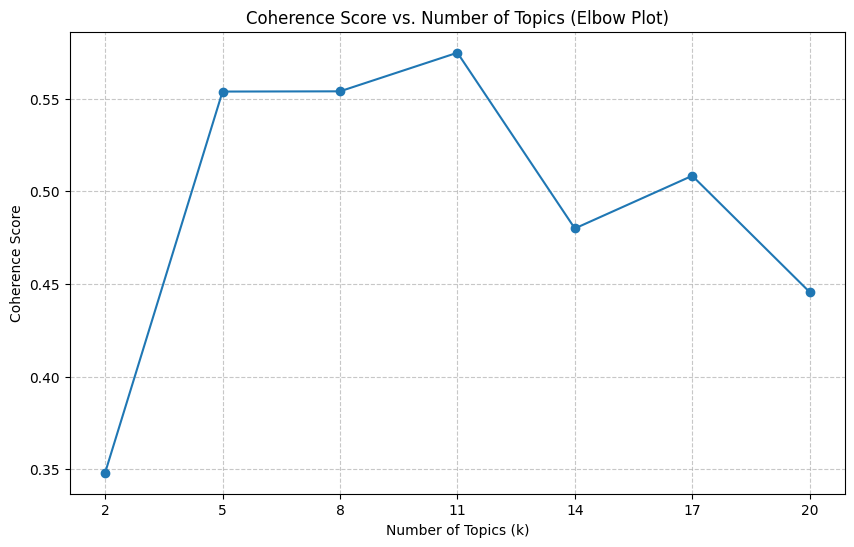

In [ ]:
# Activity 2a: Build an elbow plot of coherence vs number of topics.
# Expected output: a printed table of (k, coherence) and a line plot.
# Remember from class: the *elbow* is where the rise levels off -- it isn't
# necessarily the peak. Pick the simplest model that captures most of the gain.

from gensim.models import CoherenceModel
from gensim.models.ldamodel import LdaModel

topic_range = range(2, 21, 3) # Gives 2, 5, 8, 11, 14, 17, 20
coherence_scores = []

print("Calculating coherence scores for different numbers of topics...")
for k in topic_range:
    lda_model_k = LdaModel(
        corpus=corpus,
        id2word=dictionary.id2token,
        num_topics=k,
        passes=15,
        eval_every=None)

    coherence_model_k = CoherenceModel(
        model=lda_model_k,
        texts=texts,
        dictionary=dictionary,
        coherence='c_v')

    score = coherence_model_k.get_coherence()
    coherence_scores.append(score)
    print(f"  Topics: {k}, Coherence: {score:.4f}")

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(list(topic_range), coherence_scores, marker='o')
plt.title('Coherence Score vs. Number of Topics (Elbow Plot)')
plt.xlabel('Number of Topics (k)')
plt.ylabel('Coherence Score')
plt.xticks(list(topic_range))
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### 📝 Activity 2b: Visualize with pyLDAvis

Use `pyLDAvis` to create an interactive visualization of your 8-topic model (or whichever model you prefer from the elbow plot).

Steps:
1. Import `pyLDAvis.gensim_models` and `pyLDAvis`
2. Call `pyLDAvis.enable_notebook()`
3. Use `gensimvis.prepare()` with your model, corpus, and dictionary
4. Display the visualization

**How to explore the visualization:**
- Click on circles (topics) in the left panel to see their top words on the right
- Bigger circles = topics that cover more documents
- Topics far apart are more distinct; overlapping circles share many words
- Adjust the relevance slider (λ) to see words unique to a topic (left) vs. most frequent (right)

In [ ]:
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

# Enable notebook mode
pyLDAvis.enable_notebook()

# Build the visualization with gensimvis.prepare(model, corpus, dictionary)
vis = gensimvis.prepare(lda_model_8, corpus, dictionary)

# Display it
pyLDAvis.display(vis)

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Demo: Topic Coverage Across the Corpus

**Coverage** tells you what fraction of the corpus each topic represents on average. A topic with 25% coverage means that, across all documents, about a quarter of the content is about that topic.

In [ ]:
# Compute topic coverage for the 5-topic model
topic_coverage = np.zeros(lda_model.num_topics)

for doc_bow in corpus:
    for topic_id, proportion in lda_model.get_document_topics(
            doc_bow, minimum_probability=0):
        topic_coverage[topic_id] += proportion

# Average across all documents
topic_coverage /= len(corpus)

print("Topic coverage (5-topic model):")
for i, cov in enumerate(topic_coverage):
    print(f"  Topic {i}: {cov*100:.1f}%")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Topic coverage (5-topic model):
  Topic 0: 19.7%
  Topic 1: 23.5%
  Topic 2: 11.6%
  Topic 3: 20.4%
  Topic 4: 24.8%


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

### Demo: Comparing Topics Across Newspapers

Different newspapers may cover different topics. Let's compute topic coverage **per newspaper** to see how they differ.

In [ ]:
# See which newspapers are in our sample
print("Articles per newspaper:")
print(df['newspaper_name'].value_counts())

Articles per newspaper:
newspaper_name
Evening star. [volume] (Washington, D.C.) 1854-1972                     404
Diario las Américas.                                                   110
Evening star.                                                            49
Milford chronicle.                                                       31
The journal. (Caldwell, Ohio) 1934-1961                                  29
Montgomery County sentinel. [volume] (Rockville, Md.) 1855-1974          25
The Farmville herald. (Farmville, Va.) 1957-current                      22
St. Paul recorder. [volume] (St. Paul, Minn.) 1934-2000                  22
The Sidney herald.                                                       21
ZajednicÌŒar = Fraternalist. [volume] (Allegheny, Pa.) 1894-current      21
The Nome nugget.                                                         19
The Republican. [volume] (Oakland, Md.) 1877-current                     18
Jackson advocate. [volume] (Jackson, Miss.) 1939-

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
# Compute topic coverage per newspaper (using the 5-topic model)
newspapers = df['newspaper_name'].unique()

# Group article indices by newspaper
indices_by_newspaper = {}
for newspaper in newspapers:
    indices_by_newspaper[newspaper] = df[df['newspaper_name'] == newspaper].index.tolist()

# Compute coverage for each newspaper
topic_coverage_by_newspaper = {}
for newspaper, indices in indices_by_newspaper.items():
    coverage = np.zeros(lda_model.num_topics)
    for idx in indices:
        for topic_id, proportion in lda_model.get_document_topics(
                corpus[idx], minimum_probability=0):
            coverage[topic_id] += proportion
    coverage /= len(indices)  # average
    topic_coverage_by_newspaper[newspaper] = coverage

# Display as a DataFrame
coverage_df = pd.DataFrame.from_dict(
    topic_coverage_by_newspaper, orient='index',
    columns=[f'Topic {i}' for i in range(lda_model.num_topics)])

print("Topic coverage by newspaper (5-topic model):")
coverage_df.round(3)

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Topic coverage by newspaper (5-topic model):


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Topic 0,Topic 1,Topic 2,Topic 3,Topic 4
"Evening star. [volume] (Washington, D.C.) 1854-1972",0.158,0.358,0.019,0.165,0.301
The Chapel Hill weekly.,0.210,0.126,0.007,0.467,0.190
Montgomery County sentinel.,0.080,0.305,0.011,0.335,0.270
Diario las Américas.,0.017,0.024,0.887,0.020,0.051
"The coastland times. [volume] (Mnateo [i.e. Manteo], N.C.) 1947-1959",0.387,0.193,0.009,0.305,0.106
"The Catholic times. [volume] (Columbus, Ohio) 1951-current",0.212,0.096,0.040,0.385,0.267
"The Detroit tribune. (Detroit, Mich.) 1935-1966",0.280,0.118,0.008,0.335,0.260
Smyrna times.,0.260,0.229,0.012,0.277,0.222
Evening star.,0.146,0.350,0.016,0.178,0.310
"Geauga record. [volume] (Chardon, Geauga County, Ohio) 1952-1962",0.365,0.098,0.025,0.417,0.096


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

### 📝 Activity 2c: Compare Two Newspapers

Pick two newspapers from the dataset and compare their topic coverage using your **8-topic model** (`lda_model_8`).

Steps:
1. Compute topic coverage for the 8-topic model, grouped by newspaper (follow the demo pattern above)
2. Pick two newspapers (e.g., the one with the most articles and one with fewer)
3. Print their topic coverage side by side

After completing, answer: **What topics differ most between the two newspapers?**

*Hint: Follow the demo pattern above, but use `lda_model_8` instead of `lda_model`.*

In [ ]:
# Activity 2c: Compare topic coverage across two newspapers using lda_model_8.
# Expected output: two side-by-side breakdowns showing topic % per newspaper.
# This will reveal which themes each paper covers more / less.

# Compute topic coverage per newspaper (using the 8-topic model)
newspapers = df['newspaper_name'].unique()

# Group article indices by newspaper
indices_by_newspaper = {}
for newspaper in newspapers:
    indices_by_newspaper[newspaper] = df[df['newspaper_name'] == newspaper].index.tolist()

# Compute coverage for each newspaper using lda_model_8
topic_coverage_by_newspaper_8 = {}
for newspaper, indices in indices_by_newspaper.items():
    if len(indices) == 0:
        continue
    coverage = np.zeros(lda_model_8.num_topics)
    for idx in indices:
        for topic_id, proportion in lda_model_8.get_document_topics(
                corpus[idx], minimum_probability=0):
            coverage[topic_id] += proportion
    coverage /= len(indices)  # average
    topic_coverage_by_newspaper_8[newspaper] = coverage

# Display as a DataFrame
coverage_8_df = pd.DataFrame.from_dict(
    topic_coverage_by_newspaper_8, orient='index',
    columns=[f'Topic {i}' for i in range(lda_model_8.num_topics)])

# Select two newspapers to compare (e.g., the two with most articles)
paper1_name = df['newspaper_name'].value_counts().index[0]
paper2_name = df['newspaper_name'].value_counts().index[1]

paper1_coverage = coverage_8_df.loc[paper1_name]
paper2_coverage = coverage_8_df.loc[paper2_name]

print(f"\nTopic coverage for '{paper1_name}':")
for topic_id, proportion in paper1_coverage.items():
    label = topic_labels.get(int(topic_id.split(' ')[1]), "Unlabeled")
    print(f"  {topic_id} [{label}]: {proportion*100:.2f}%")

print(f"\nTopic coverage for '{paper2_name}':")
for topic_id, proportion in paper2_coverage.items():
    label = topic_labels.get(int(topic_id.split(' ')[1]), "Unlabeled")
    print(f"  {topic_id} [{label}]: {proportion*100:.2f}%")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag


Topic coverage for 'Evening star. [volume] (Washington, D.C.) 1854-1972':
  Topic 0 [Legal/Sales Transactions]: 6.85%
  Topic 1 [Real Estate/Housing]: 31.53%
  Topic 2 [Politics/Government/Meetings]: 11.16%
  Topic 3 [Spanish Language Content]: 1.65%
  Topic 4 [Global/National Affairs]: 13.36%
  Topic 5 [Social Events/Personal News]: 9.91%
  Topic 6 [Church/Community Events]: 9.48%
  Topic 7 [Court/State Law]: 16.07%

Topic coverage for 'Diario las Américas.':
  Topic 0 [Legal/Sales Transactions]: 1.44%
  Topic 1 [Real Estate/Housing]: 1.41%
  Topic 2 [Politics/Government/Meetings]: 1.49%
  Topic 3 [Spanish Language Content]: 87.78%
  Topic 4 [Global/National Affairs]: 1.55%
  Topic 5 [Social Events/Personal News]: 1.99%
  Topic 6 [Church/Community Events]: 1.00%
  Topic 7 [Court/State Law]: 3.36%


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

---
# 🏠 AFTER-CLASS ACTIVITIES

Complete these on your own after lecture (~30 min total).

---

## Activity 3: Single-Document Topic Analysis (~15 min)

In Activity 1c you looked at one document. Now explore several documents to build intuition for how LDA assigns topics.

### 📝 Activity 3a: Find a Document Dominated by One Topic

Loop through the first 50 documents and find one where a **single topic accounts for 80% or more** of the document.

Steps:
1. Loop through `range(50)`
2. For each document, get its topic distribution with `lda_model_8.get_document_topics(corpus[i])`
3. Check if any topic has proportion > 0.80
4. Print the document index, dominant topic, and the first 200 characters of text

*Hint: `max(doc_topics, key=lambda x: x[1])` gives you the topic with the highest proportion.*

In [ ]:
# Activity 3a: Find a document where ONE topic accounts for 80%+ of the text.
# Expected output: a printed line with the doc index, dominant topic + label,
# and the first ~200 characters of the article.

for i in range(50):
    doc_topics = lda_model_8.get_document_topics(corpus[i])
    if doc_topics:
        # Find the topic with the highest proportion
        dominant_topic = max(doc_topics, key=lambda x: x[1])
        topic_id, proportion = dominant_topic

        if proportion > 0.80:
            label = topic_labels.get(topic_id, "Unlabeled")
            print(f"Document {i} is dominated by Topic {topic_id} [{label}] with {proportion*100:.2f}%:")
            print(df.loc[i, 'article'][:200])
            print()
            break # Stop after finding the first one

Document 8 is dominated by Topic 2 [Politics/Government/Meetings] with 98.86%:
Harvey Brickhouse won the 1858 Tyrrell County All corn production contest with a yield of LOT bushels per acre. Coming in second with yield of 101.1 bushels per acre was Ben Brickhouse, Harvey's broth



/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

### 📝 Activity 3b: Find a Document with Mixed Topics

Now find a document where **no single topic exceeds 40%** — meaning it's a true mixture of several themes.

Steps:
1. Loop through the first 100 documents
2. For each, check if the max topic proportion is < 0.40
3. Print the full topic breakdown and the first 300 characters of text

In [ ]:
# Activity 3b: Find a document where NO topic exceeds 40% -- a true mixture.
# Expected output: the full topic breakdown for one mixed-theme doc plus a
# ~300-char snippet so you can see why several topics fit.

for i in range(100):
    doc_topics = lda_model_8.get_document_topics(corpus[i])
    if doc_topics:
        # Find the maximum topic proportion in the document
        max_proportion = max([proportion for topic_id, proportion in doc_topics])

        if max_proportion < 0.40:
            print(f"Document {i} is a mixture of topics (max topic proportion < 40%):")
            print(df.loc[i, 'article'][:300])
            print("\nFull Topic Breakdown:")
            for topic_id, proportion in doc_topics:
                label = topic_labels.get(topic_id, "Unlabeled")
                print(f"  Topic {topic_id} [{label}]: {proportion*100:.2f}%")
            print()
            break # Stop after finding the first one

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Document 4 is a mixture of topics (max topic proportion < 40%):
- ~ % tofzpa E.2s ~

Full Topic Breakdown:
  Topic 0 [Legal/Sales Transactions]: 12.50%
  Topic 1 [Real Estate/Housing]: 12.50%
  Topic 2 [Politics/Government/Meetings]: 12.50%
  Topic 3 [Spanish Language Content]: 12.50%
  Topic 4 [Global/National Affairs]: 12.50%
  Topic 5 [Social Events/Personal News]: 12.50%
  Topic 6 [Church/Community Events]: 12.50%
  Topic 7 [Court/State Law]: 12.50%



/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

---
## Activity 4: Topic Coverage Bar Chart (~15 min)

Create a **grouped bar chart** comparing topic coverage across two newspapers. This is a great way to visually communicate how different sources emphasize different themes.

### 📝 Activity 4a: Grouped Bar Chart

Using the topic coverage data from Activity 2c, create a grouped bar chart with:
- X-axis: Topic numbers (0 through 7)
- Y-axis: Coverage percentage
- Two bars per topic: one for each newspaper
- A legend identifying which bar is which newspaper

Steps:
1. Use `np.arange(8)` for x positions
2. Use `plt.bar(x - width/2, ...)` for the first newspaper
3. Use `plt.bar(x + width/2, ...)` for the second newspaper
4. Add labels, title, and legend

*Hint: Look back at the grouped bar chart demo from Lecture 6.*

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

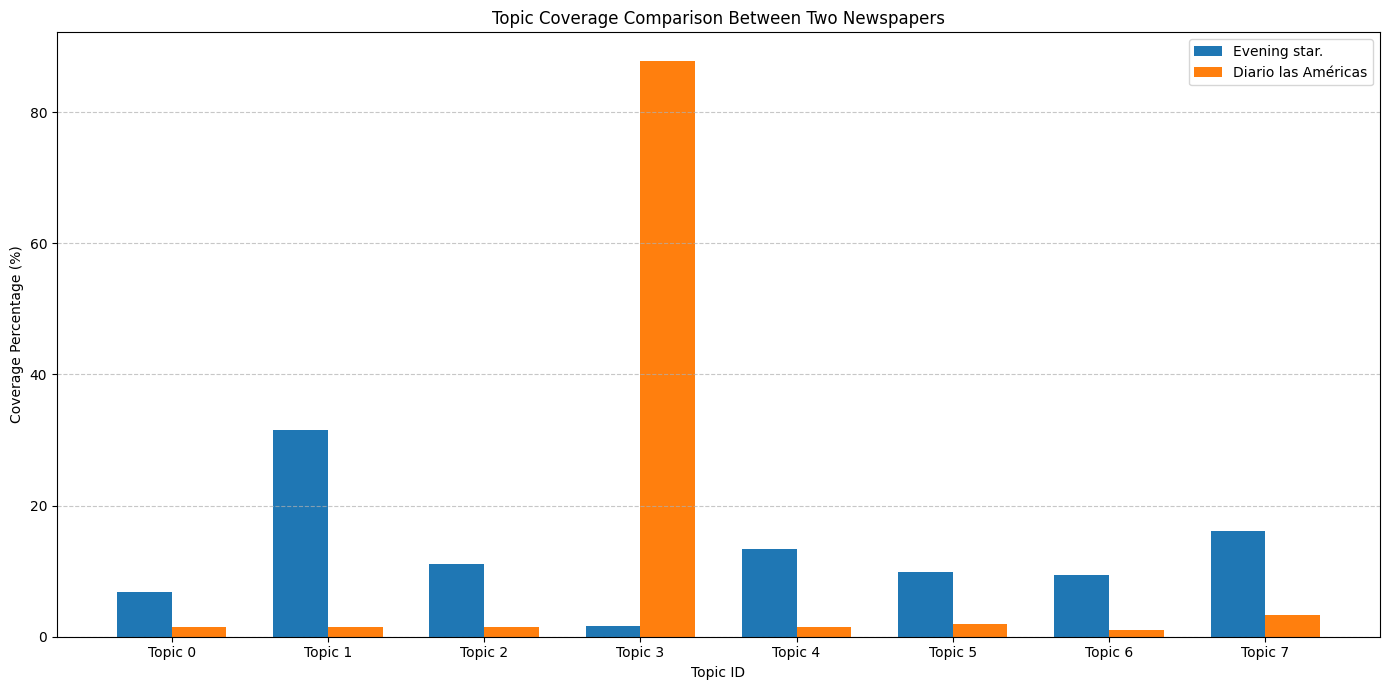

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
# Activity 4a: Build a grouped bar chart comparing two newspapers across the 8 topics.
# Expected output: 8 pairs of bars, with a legend, axis labels, and title.

# Get the topic coverage values for the two selected newspapers
paper1_values = paper1_coverage.values * 100 # Convert to percentage
paper2_values = paper2_coverage.values * 100 # Convert to percentage

topics = np.arange(lda_model_8.num_topics) # X-axis positions for topics (0 to 7)
width = 0.35 # Width of each bar

fig, ax = plt.subplots(figsize=(14, 7))

# Plot bars for the first newspaper
rects1 = ax.bar(topics - width/2, paper1_values, width, label=paper1_name.split('[volume]')[0].strip())
# Plot bars for the second newspaper
rects2 = ax.bar(topics + width/2, paper2_values, width, label=paper2_name.split('.')[0].strip())

# Add labels, title, and legend
ax.set_xlabel('Topic ID')
ax.set_ylabel('Coverage Percentage (%)')
ax.set_title('Topic Coverage Comparison Between Two Newspapers')
ax.set_xticks(topics) # Set x-ticks to be at the center of the grouped bars
ax.set_xticklabels([f'Topic {i}' for i in topics])
ax.legend()

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 📝 Activity 4b: Interpret the Chart

Based on your grouped bar chart, answer these questions in the cell below:

1. Which topic does Newspaper 1 cover more than Newspaper 2?
2. Which topic does Newspaper 2 cover more?
3. Are there any topics where both newspapers have similar coverage?
4. Do the differences make sense given what you know about the topic words?

In [ ]:
# Activity 4b: Write your interpretation as comments below.
# This is reflective writing -- there is no single right answer.

# Based on the grouped bar chart:
# 1. Which topic does Newspaper 1 cover more than Newspaper 2?
#    Newspaper 1 ('Evening star.') covers Topic 1 [Real Estate/Housing] (31.53%) and Topic 7 [Court/State Law] (16.07%) significantly more than Newspaper 2 ('Diario las Américas.').
#    It also covers Topic 2 [Politics/Government/Meetings], Topic 4 [Global/National Affairs], Topic 5 [Social Events/Personal News], and Topic 6 [Church/Community Events] more.

# 2. Which topic does Newspaper 2 cover more?
#    Newspaper 2 ('Diario las Américas.') covers Topic 3 [Spanish Language Content] (87.78%) overwhelmingly more than Newspaper 1 (1.65%).

# 3. Are there any topics where both newspapers have similar coverage?
#    There are no topics with very similar coverage. The proportions for all topics show notable differences, primarily due to Newspaper 2's strong focus on Topic 3.

# 4. Do the differences make sense given what you know about the topic words?
#    Yes, the differences make perfect sense. 'Diario las Américas.' likely caters to a Spanish-speaking audience, hence its dominant coverage of Topic 3, which is labeled 'Spanish Language Content'. The 'Evening star.', a general American newspaper, shows a broader distribution across various topics like local news, real estate, and legal matters.

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

---
## Summary

Here's what you practiced in this notebook:

| Activity | Topic | Key Methods |
|----------|-------|-------------|
| 1a | Train LDA with 8 topics | `LdaModel()`, `print_topics()` |
| 1b | Label topics | Human interpretation of word lists |
| 1c | Single document topics | `get_document_topics()` |
| 2a | Coherence elbow plot | `CoherenceModel()`, `plt.plot()` |
| 2b | pyLDAvis visualization | `gensimvis.prepare()`, `pyLDAvis.display()` |
| 2c | Compare newspapers | Topic coverage by group |
| 3a | Dominant-topic documents | Filtering by proportion |
| 3b | Mixed-topic documents | Filtering by max proportion |
| 4a | Grouped bar chart | `plt.bar()` with offsets |
| 4b | Interpret results | Written analysis |

**Key takeaway:** Topic modeling lets you discover themes in text data without any labels. The workflow is: clean text → build dictionary & corpus → train LDA → interpret and tune.

---
## Reminders

- **Submit** this notebook via Canvas by the deadline.
- **Office hours**: Check the syllabus for times and location.
- **Project #2**: Make sure you are making progress on your unstructured data project. Reach out if you have questions!